### **NYC Airbnb Room Type Classification**

**Goal**: Predict the room_type of an Airbnb listing (Entire home/apt, Private room, or Shared room) using listing attributes such as price, location, availability, and review activity.

**What this notebook covers (the full ML lifecycle):**

1. Problem framing & data loading
2. Exploratory Data Analysis (EDA) — univariate, bivariate, skewness, outliers
3. Data cleaning & feature engineering
4. Train / test split
5. Preprocessing with ColumnTransformer + Pipeline
6. Baseline model
8. Multiple candidate algorithms (Logistic Regression, Decision Tree, Random Forest, Gradient Boosting)
9. Model comparison (cross-validation)
10. Hyperparameter tuning of the best model
11. Final evaluation on the untouched test set
12. Feature importance
13. Saving the final pipeline (model artifact)
14. Conclusion & next steps



**1. Import Libraries**

In [34]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

**2. Load the Dataset**

In [35]:
import kagglehub
import os

# Download latest version
path = kagglehub.dataset_download("dgomonov/new-york-city-airbnb-open-data")

# print("Path to dataset files:", path)

df = pd.read_csv(os.path.join(path, "AB_NYC_2019.csv"))

In [36]:
df.head()

,id,name,host_id,host_name,neighbourhood_group,neighbourhood,latitude,longitude,room_type,price,minimum_nights,number_of_reviews,last_review,reviews_per_month,calculated_host_listings_count,availability_365
0,2539,Clean & quiet apt home by the park,2787,John,Brooklyn,Kensington,40.64749,-73.97237,Private room,149,1,9,2018-10-19,0.21,6,365
1,2595,Skylit Midtown Castle,2845,Jennifer,Manhattan,Midtown,40.75362,-73.98377,Entire home/apt,225,1,45,2019-05-21,0.38,2,355
2,3647,THE VILLAGE OF HARLEM....NEW YORK !,4632,Elisabeth,Manhattan,Harlem,40.80902,-73.94190,Private room,150,3,0,NaN,NaN,1,365
3,3831,Cozy Entire Floor of Brownstone,4869,LisaRoxanne,Brooklyn,Clinton Hill,40.68514,-73.95976,Entire home/apt,89,1,270,2019-07-05,4.64,1,194
4,5022,Entire Apt: Spacious Studio/Loft by central park,7192,Laura,Manhattan,East Harlem,40.79851,-73.94399,Entire home/apt,80,10,9,2018-11-19,0.10,1,0


In [37]:
df.shape

(48895, 16)

In [38]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48895 entries, 0 to 48894
Data columns (total 16 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   id                              48895 non-null  int64  
 1   name                            48879 non-null  str    
 2   host_id                         48895 non-null  int64  
 3   host_name                       48874 non-null  str    
 4   neighbourhood_group             48895 non-null  str    
 5   neighbourhood                   48895 non-null  str    
 6   latitude                        48895 non-null  float64
 7   longitude                       48895 non-null  float64
 8   room_type                       48895 non-null  str    
 9   price                           48895 non-null  int64  
 10  minimum_nights                  48895 non-null  int64  
 11  number_of_reviews               48895 non-null  int64  
 12  last_review                     38843 non-n

In [39]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
id,48895.0,1.901714e+07,1.098311e+07,2539.00000,9.471945e+06,1.967728e+07,2.915218e+07,3.648724e+07
host_id,48895.0,6.762001e+07,7.861097e+07,2438.00000,7.822033e+06,3.079382e+07,1.074344e+08,2.743213e+08
latitude,48895.0,4.072895e+01,5.453008e-02,40.49979,4.069010e+01,4.072307e+01,4.076311e+01,4.091306e+01
longitude,48895.0,-7.395217e+01,4.615674e-02,-74.24442,-7.398307e+01,-7.395568e+01,-7.393627e+01,-7.371299e+01
price,48895.0,1.527207e+02,2.401542e+02,0.00000,6.900000e+01,1.060000e+02,1.750000e+02,1.000000e+04
minimum_nights,48895.0,7.029962e+00,2.051055e+01,1.00000,1.000000e+00,3.000000e+00,5.000000e+00,1.250000e+03
number_of_reviews,48895.0,2.327447e+01,4.455058e+01,0.00000,1.000000e+00,5.000000e+00,2.400000e+01,6.290000e+02
reviews_per_month,38843.0,1.373221e+00,1.680442e+00,0.01000,1.900000e-01,7.200000e-01,2.020000e+00,5.850000e+01
calculated_host_listings_count,48895.0,7.143982e+00,3.295252e+01,1.00000,1.000000e+00,1.000000e+00,2.000000e+00,3.270000e+02
availability_365,48895.0,1.127813e+02,1.316223e+02,0.00000,0.000000e+00,4.500000e+01,2.270000e+02,3.650000e+02


**3. Exploratory Data Analysis (EDA)**

We explore the data in the standard order every ML engineer follows:

- Missing values
- Univariate analysis (one variable at a time — distributions, skewness)
- Bivariate analysis (relationship between features and the target)
- Correlation between numeric features
- Outlier inspection

**3.1 Missing Values**

In [40]:
missing = df.isnull().sum()
missing[missing>0]

name                    16
host_name               21
last_review          10052
reviews_per_month    10052
dtype: int64

**3.2 Target Variable — room_type**

In [45]:
df['room_type'].unique().tolist()

['Private room', 'Entire home/apt', 'Shared room']

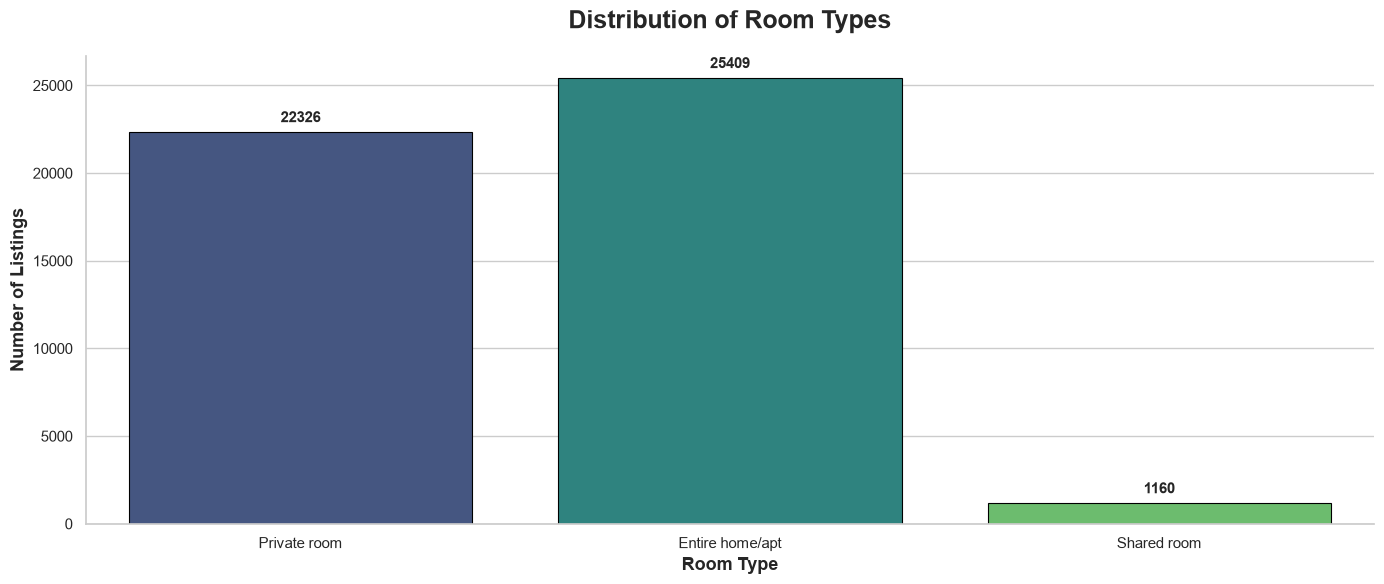

In [42]:
sns.set_theme(style="whitegrid", context="notebook")

plt.figure(figsize=(14, 6))

ax = sns.countplot(
    x='room_type',
    hue='room_type',
    data=df,
    palette='viridis',
    edgecolor='black',
    linewidth=0.8,
    legend=False
)

# Display count labels
for container in ax.containers:
    ax.bar_label(container, padding=5, fontsize=11, fontweight='bold')

plt.title('Distribution of Room Types', fontsize=18, fontweight='bold', pad=20)
plt.xlabel('Room Type', fontsize=13, fontweight='bold')
plt.ylabel('Number of Listings', fontsize=13, fontweight='bold')

plt.xticks(fontsize=11)
plt.yticks(fontsize=11)

sns.despine()
plt.tight_layout()
plt.show()

**3.3 Univariate Analysis — Numeric Features**

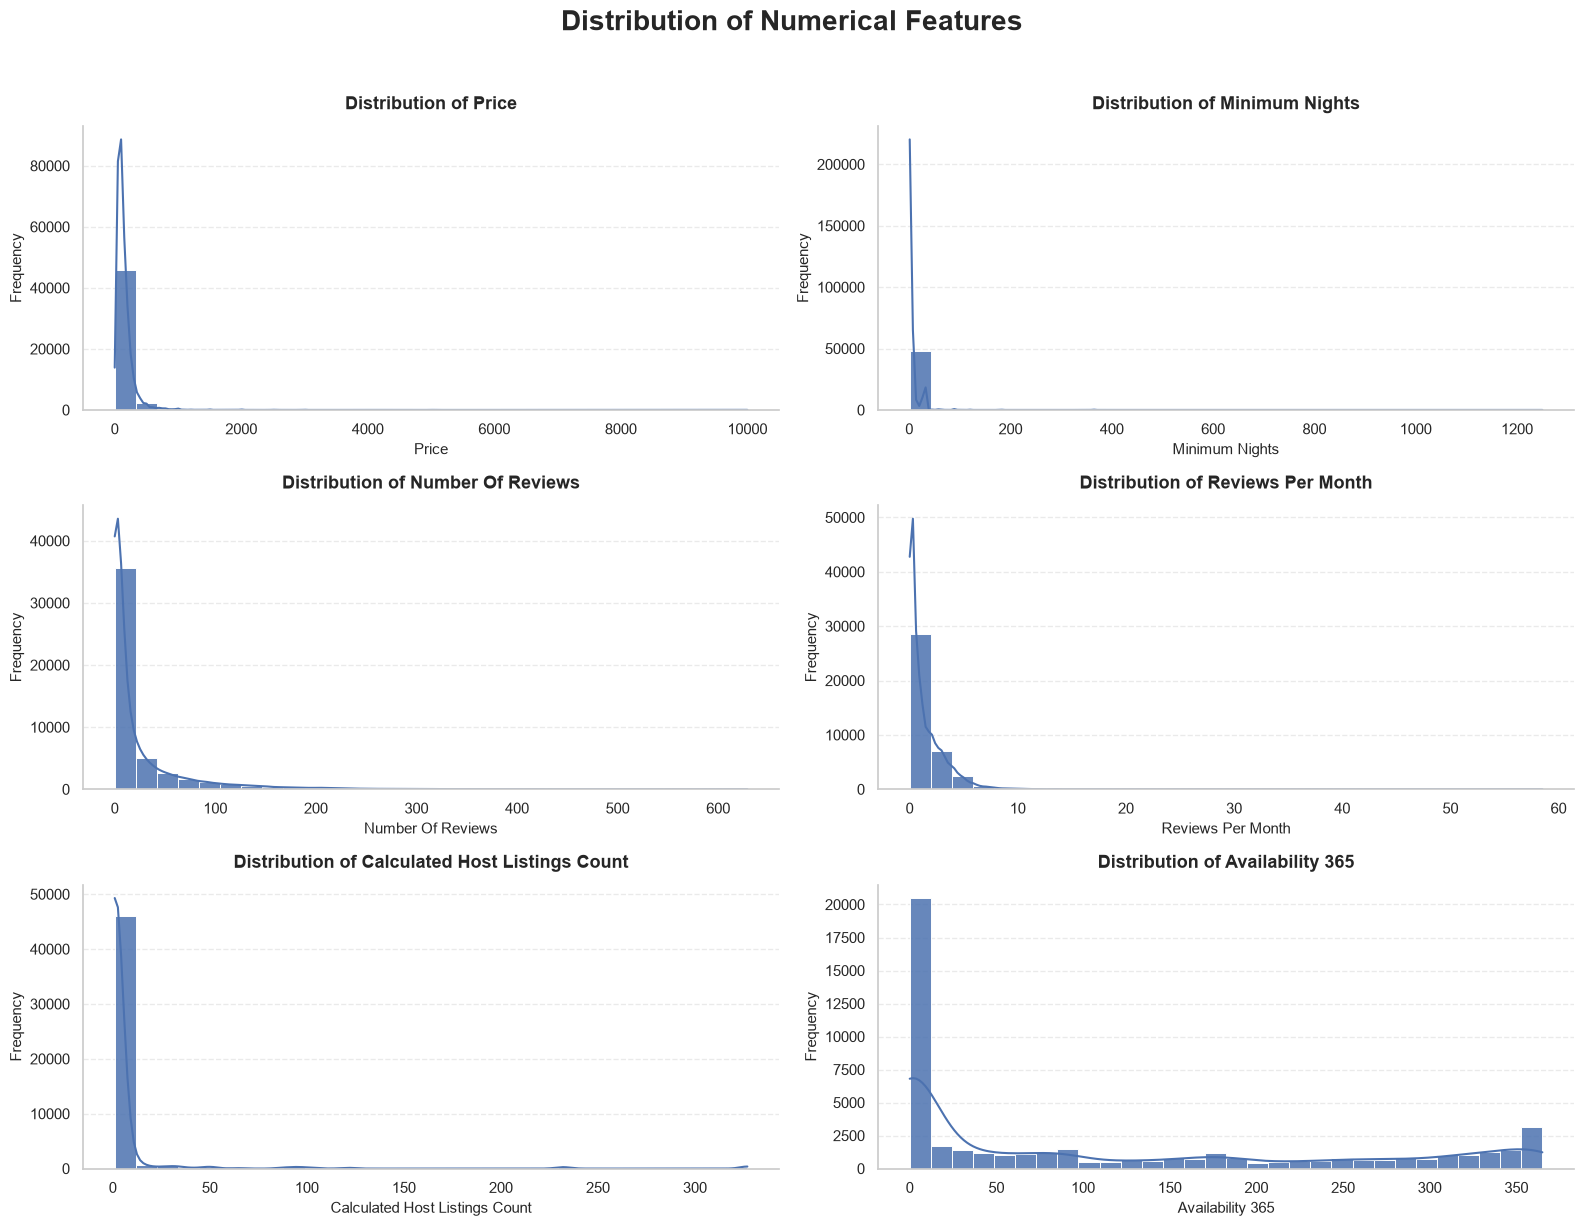

In [46]:
numerical_cols = [
    "price",
    "minimum_nights",
    "number_of_reviews",
    "reviews_per_month",
    "calculated_host_listings_count",
    "availability_365"
]

# Set visual theme
sns.set_theme(style="whitegrid", context="notebook")

# Create subplot grid
fig, axes = plt.subplots(3, 2, figsize=(16, 12))

fig.suptitle(
    "Distribution of Numerical Features",
    fontsize=20,
    fontweight="bold",
    y=1.02
)

# Flatten axes for iteration
axes = axes.flatten()

for i, col in enumerate(numerical_cols):

    sns.histplot(
        data=df,
        x=col,
        bins=30,
        kde=True,
        color="#4C72B0",
        edgecolor="white",
        linewidth=0.7,
        alpha=0.85,
        ax=axes[i]
    )

    axes[i].set_title(
        f"Distribution of {col.replace('_', ' ').title()}",
        fontsize=13,
        fontweight="bold",
        pad=12
    )

    axes[i].set_xlabel(col.replace("_", " ").title(), fontsize=11)
    axes[i].set_ylabel("Frequency", fontsize=11)

    axes[i].grid(axis="y", linestyle="--", alpha=0.4)
    axes[i].grid(axis="x", visible=False)

    sns.despine(ax=axes[i])

# Adjust spacing
plt.tight_layout()

plt.show()

**3.4 Univariate Analysis — Categorical Features**

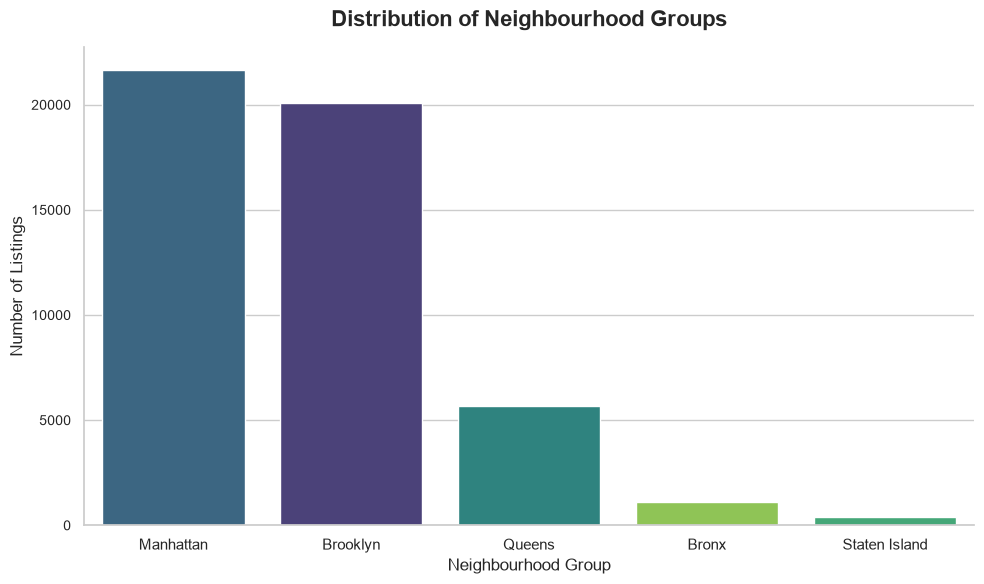

In [47]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x='neighbourhood_group',
    hue='neighbourhood_group',
    palette='viridis',
    order=df['neighbourhood_group'].value_counts().index,
    legend=False
)

plt.title('Distribution of Neighbourhood Groups', fontsize=16, fontweight='bold', pad=15)
plt.xlabel('Neighbourhood Group', fontsize=12)
plt.ylabel('Number of Listings', fontsize=12)

plt.xticks(fontsize=11)
plt.yticks(fontsize=10)

sns.despine()
plt.tight_layout()
plt.show()

**3.5 Bivariate Analysis — Features vs Target**

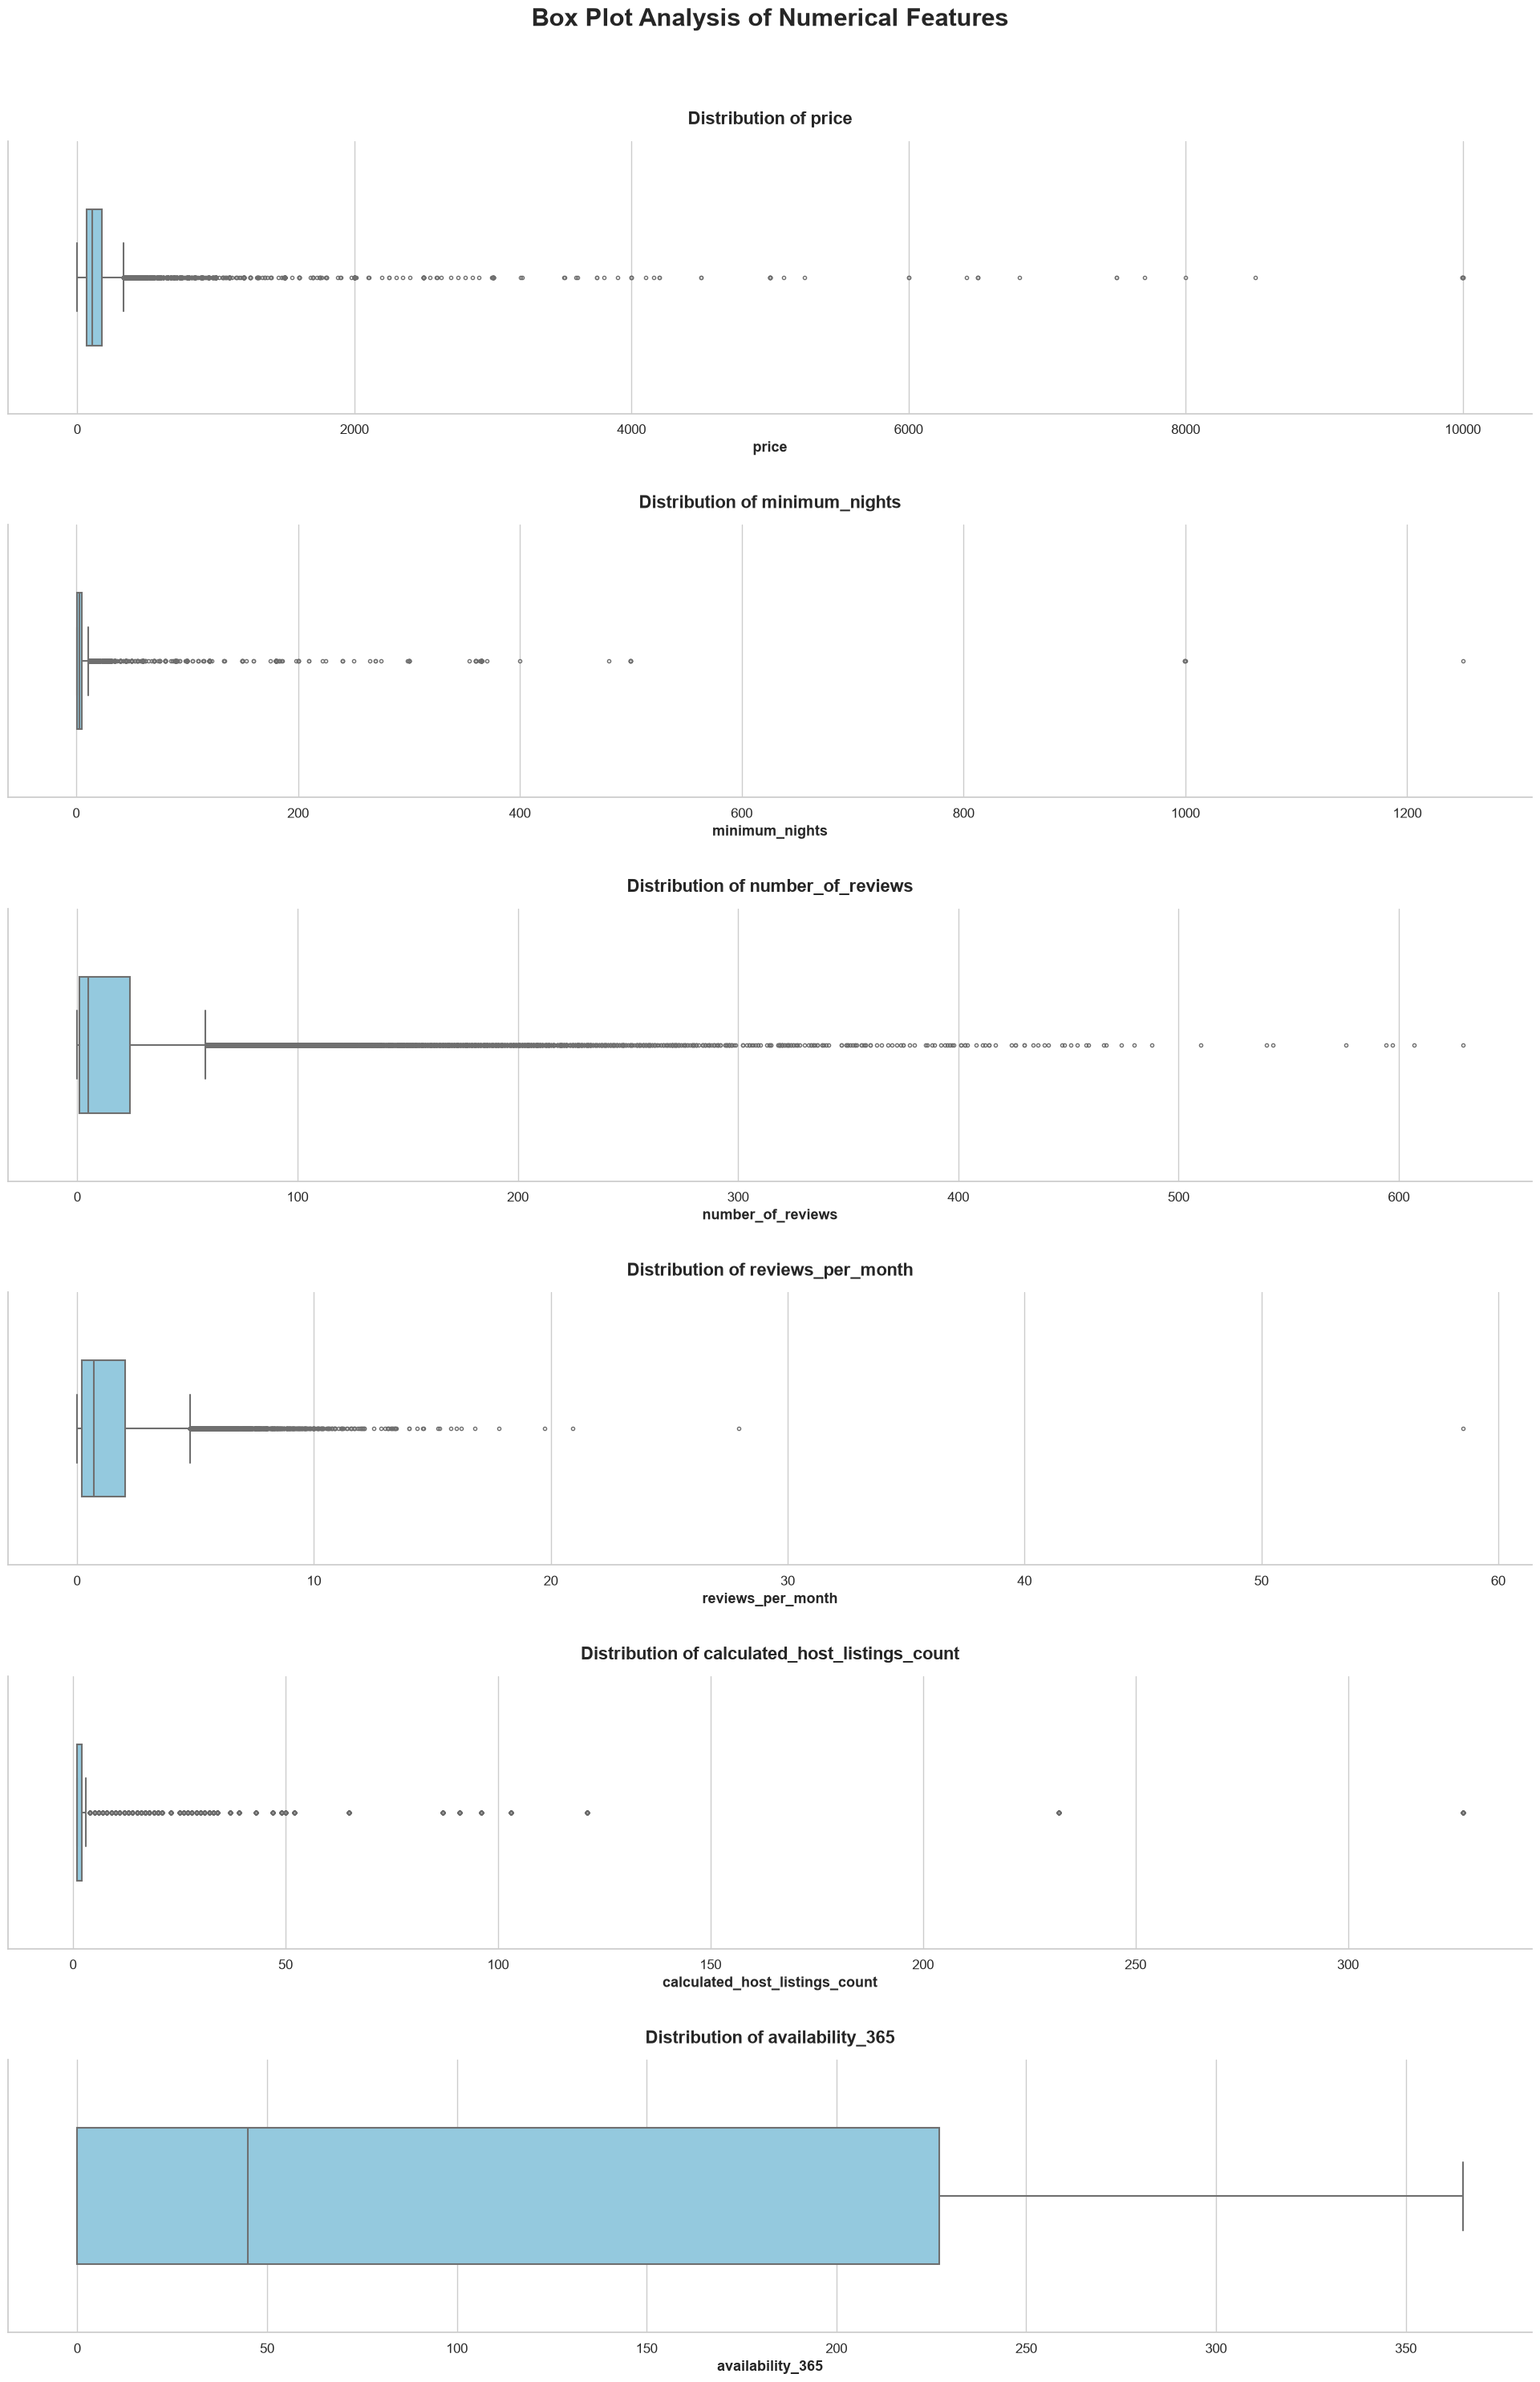

In [54]:
sns.set_theme(style="whitegrid", palette="muted")

# Create 6 vertically stacked plots
fig, axes = plt.subplots(
    nrows=6,
    ncols=1,
    figsize=(20, 30)
)

for ax, col in zip(axes, numerical_cols):

    sns.boxplot(
        data=df,
        x=col,
        ax=ax,
        color="skyblue",
        width=0.5,
        fliersize=3,
        linewidth=1.5
    )

    ax.set_title(
        f"Distribution of {col}",
        fontsize=16,
        fontweight="bold",
        pad=15
    )

    ax.set_xlabel(col, fontsize=13, fontweight="bold")
    ax.set_ylabel("")

    # Improve tick readability
    ax.tick_params(axis="x", labelsize=12)

    # Remove unnecessary borders
    sns.despine(ax=ax)

plt.suptitle(
    "Box Plot Analysis of Numerical Features",
    fontsize=22,
    fontweight="bold",
    y=1.0
)

plt.tight_layout(pad=3.0)
plt.show()

**For Airbnb datasets, price often contains extreme outliers and is highly right-skewed.**

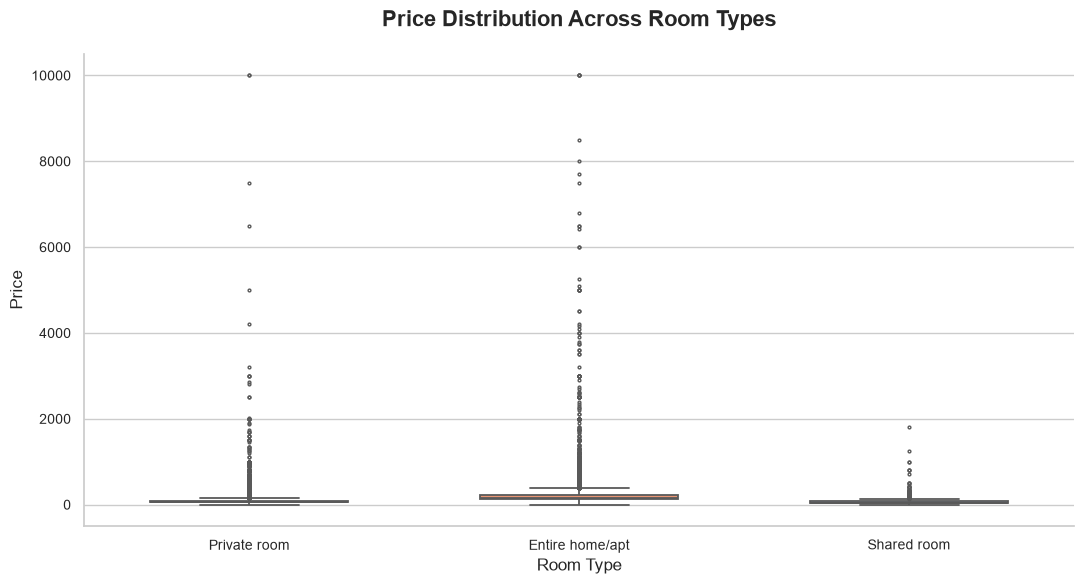

In [55]:
plt.figure(figsize=(11, 6))

sns.set_theme(style="whitegrid", context="notebook")

sns.boxplot(
    data=df,
    x="room_type",
    y="price",
    hue="room_type",
    palette="Set2",
    width=0.6,
    linewidth=1.3,
    fliersize=2,
    legend=False
)

plt.title("Price Distribution Across Room Types",
          fontsize=16, fontweight="bold", pad=20)

plt.xlabel("Room Type", fontsize=12)
plt.ylabel("Price", fontsize=12)

plt.xticks(fontsize=10)
plt.yticks(fontsize=10)

sns.despine()
plt.tight_layout()
plt.show()

**3.6 Correlation Between Numeric Features**

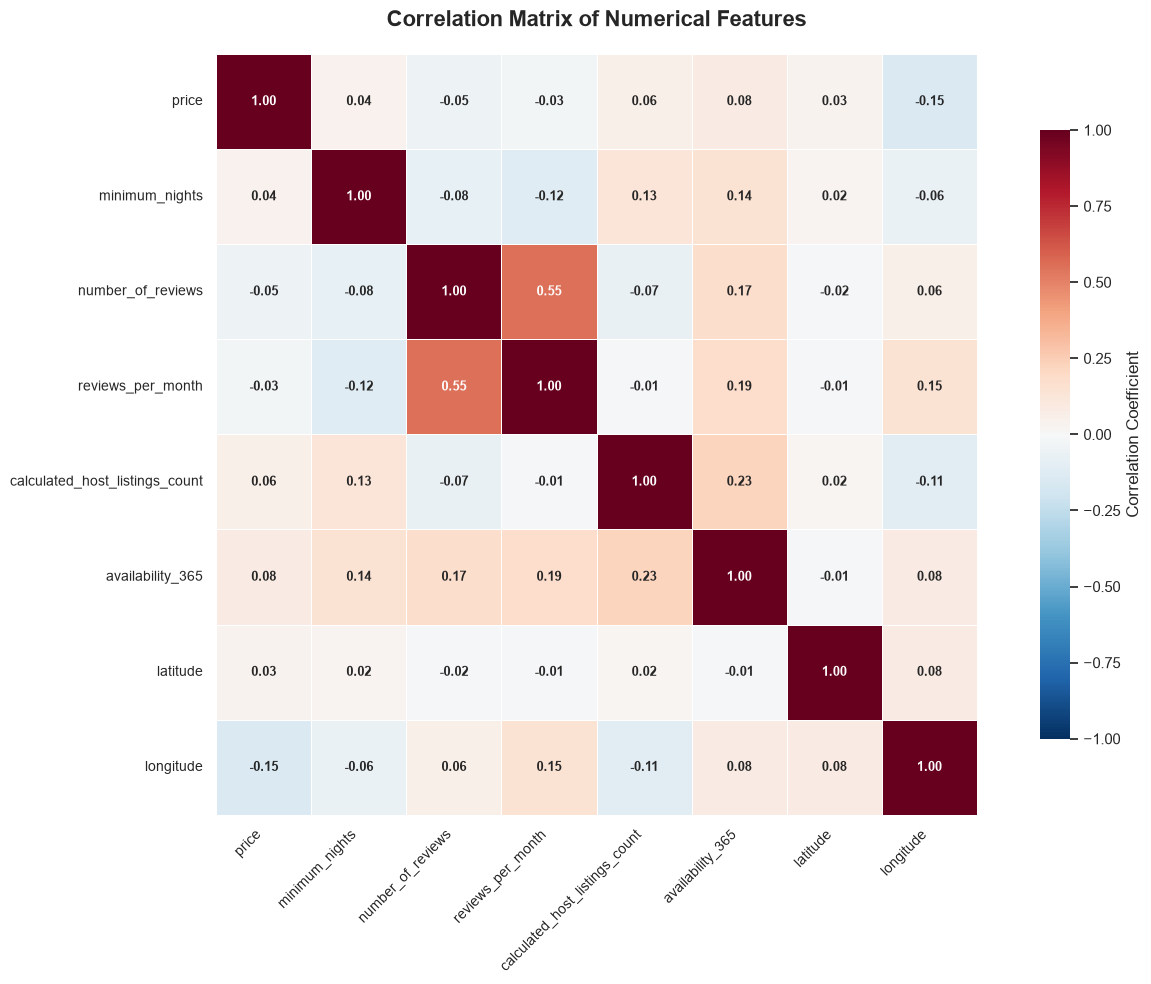

In [56]:
# Calculate correlation matrix
corr = df[numerical_cols + ['latitude', 'longitude']].corr()

# Set figure size
plt.figure(figsize=(14, 10))

# Create heatmap
sns.heatmap(
    corr,
    annot=True,
    cmap='RdBu_r',
    fmt='.2f',
    linewidths=0.5,
    linecolor='white',
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    annot_kws={
        'size': 9,
        'weight': 'bold'
    },
    cbar_kws={
        'shrink': 0.8,
        'label': 'Correlation Coefficient'
    }
)

# Customize title and labels
plt.title(
    'Correlation Matrix of Numerical Features',
    fontsize=16,
    fontweight='bold',
    pad=20
)

plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(rotation=0, fontsize=10)

plt.tight_layout()
plt.show()